# Your First Classification Model
## Who has a bank account? Financial inclusion in East Africa

**Audience:** data-science new joiners · **Time:** about 90–120 minutes · **Level:** beginner

---

### What you will be able to do by the end
1. Explain what **classification** is and how it differs from regression.
2. Load a real dataset into pandas in one line.
3. Explore data with quick checks and plots, and turn findings into insights.
4. Convert text (categorical) columns into numbers with **one-hot encoding**.
5. Split data into **training** and **test** sets, and explain why.
6. Train three classifiers: **Logistic Regression**, **Decision Tree** and **Random Forest**.
7. Evaluate them with **accuracy, precision, recall, F1** and the **confusion matrix**.
8. Explain why accuracy is misleading on **imbalanced** data, and fix it.
9. Use a trained model to make a prediction for a new person.

### The workflow we will follow
```
 1. Frame the problem  →  2. Load data  →  3. Explore  →  4. Prepare (encode + split)
 →  5. Baseline  →  6. Train models  →  7. Evaluate  →  8. Improve  →  9. Explain & predict
```
This same workflow applies to almost every classification project you will meet at work.

## 1. Frame the problem

**Classification** = predicting a *category* (a label), not a number.

| Question | Type | Why |
|---|---|---|
| Will this customer churn? (yes/no) | Classification | answer is a category |
| Will this loan be repaid? | Classification | answer is a category |
| How much will this customer deposit next month? | Regression | answer is a number |

**Our question:** given basic facts about a person (country, age, education, job, phone access…), **does this person have a bank account?**

This is **binary classification**: exactly two possible answers, *Yes* or *No*.

### Why it matters
Financial inclusion is one of the main drivers of economic growth in Africa. A bank account lets people save safely, get credit and make payments. Yet in this survey only about **1 in 7** adults has one.

A model like this helps banks, fintechs, NGOs and governments to:
- understand **which groups are left out** (and why), and
- **target** outreach, products and policy at the right people.

### The data
The *Financial Inclusion in Africa* dataset (published on [Zindi](https://zindi.africa/competitions/financial-inclusion-in-africa/data)) comes from the Finscope surveys run from 2016 to 2018 in **Kenya, Rwanda, Tanzania and Uganda**. It covers about 23,500 respondents.

## 2. Setup: import the libraries

| Library | What we use it for |
|---|---|
| `pandas` | tables of data (DataFrames) |
| `numpy` | fast maths on arrays |
| `matplotlib` / `seaborn` | charts |
| `scikit-learn` (`sklearn`) | encoding, models and evaluation tools |

If anything is missing, run `pip install pandas numpy matplotlib seaborn scikit-learn` in a terminal first.

In [1]:
# --- Core data tools ---
import os
import numpy as np
import pandas as pd

# --- Plotting ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- scikit-learn: preprocessing, splitting, models, metrics ---
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_auc_score, roc_curve,
)

# Make results reproducible: the same "random" choices every time we run the notebook.
RANDOM_STATE = 42

# Consistent colours for the two classes throughout the notebook.
COLORS = {"Yes": "#2a78d6", "No": "#eb6834"}
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)

Libraries loaded ✅


## 3. Load the data

`pd.read_csv()` can read a file from your computer **or straight from a web address (URL)**.

The cell below:
1. uses `Train.csv` if it sits in the same folder as this notebook (works offline), otherwise
2. downloads it from a public GitHub copy of the Zindi data.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/AchiengJoy/Financial-Inclusion/main/Datasets/Train_v2.csv"
LOCAL_FILE = "Train.csv"

if os.path.exists(LOCAL_FILE):
    df = pd.read_csv(LOCAL_FILE)
    print("Loaded from local file:", LOCAL_FILE)
else:
    df = pd.read_csv(DATA_URL)
    print("Loaded from URL")

print("Rows (people):", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Loaded from local file: Train.csv
Rows (people): 23524
Columns: 13


,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


In [ ]:
DATA_URL = "https://raw.githubusercontent.com/AchiengJoy/Financial-Inclusion/main/Datasets/Train_v2.csv"
df = pd.read_csv(DATA_URL)
df.sample(10)

## 4. Explore the data 

Before modelling, always get to know the data. Five quick questions:
1. What do the columns mean?
2. Are there missing values?
3. How balanced are the classes (The target variable classes)?
4. Which groups are more likely to have an account?
5. Which columns should we **not** use?

### 4.1 What do the columns mean?

| Column | Meaning | Type |
|---|---|---|
| `country` | Kenya, Rwanda, Tanzania or Uganda | categorical |
| `year` | survey year (2016–2018) | number |
| `uniqueid` | respondent ID (not unique across countries) | ID |
| **`bank_account`** | **Yes / No: our target** | **label** |
| `location_type` | Rural or Urban | categorical |
| `cellphone_access` | Yes / No | categorical |
| `household_size` | number of people in the household | number |
| `age_of_respondent` | age in years | number |
| `gender_of_respondent` | Male / Female | categorical |
| `relationship_with_head` | relationship to head of household | categorical |
| `marital_status` | married, single, widowed… | categorical |
| `education_level` | highest level of education | categorical |
| `job_type` | type of employment | categorical |

In [3]:
# A quick structural summary: column names, types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 23524 non-null  str  
 1   year                    23524 non-null  int64
 2   uniqueid                23524 non-null  str  
 3   bank_account            23524 non-null  str  
 4   location_type           23524 non-null  str  
 5   cellphone_access        23524 non-null  str  
 6   household_size          23524 non-null  int64
 7   age_of_respondent       23524 non-null  int64
 8   gender_of_respondent    23524 non-null  str  
 9   relationship_with_head  23524 non-null  str  
 10  marital_status          23524 non-null  str  
 11  education_level         23524 non-null  str  
 12  job_type                23524 non-null  str  
dtypes: int64(3), str(10)
memory usage: 2.3 MB


### 4.2 Are there missing values or duplicate rows?

In [4]:
print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())
# This dataset is clean. In real projects you will usually need to handle missing values
# (drop rows, or fill them with a sensible value such as the median or most common category).

Missing values per column:
country                   0
year                      0
uniqueid                  0
bank_account              0
location_type             0
cellphone_access          0
household_size            0
age_of_respondent         0
gender_of_respondent      0
relationship_with_head    0
marital_status            0
education_level           0
job_type                  0

Duplicate rows: 0


### 4.3 How balanced are the classes?
This is the most important check in any classification project. If one answer is far more common than the other, a model can look "accurate" while being useless.

,count,percent
bank_account,,
No,20212,85.9
Yes,3312,14.1


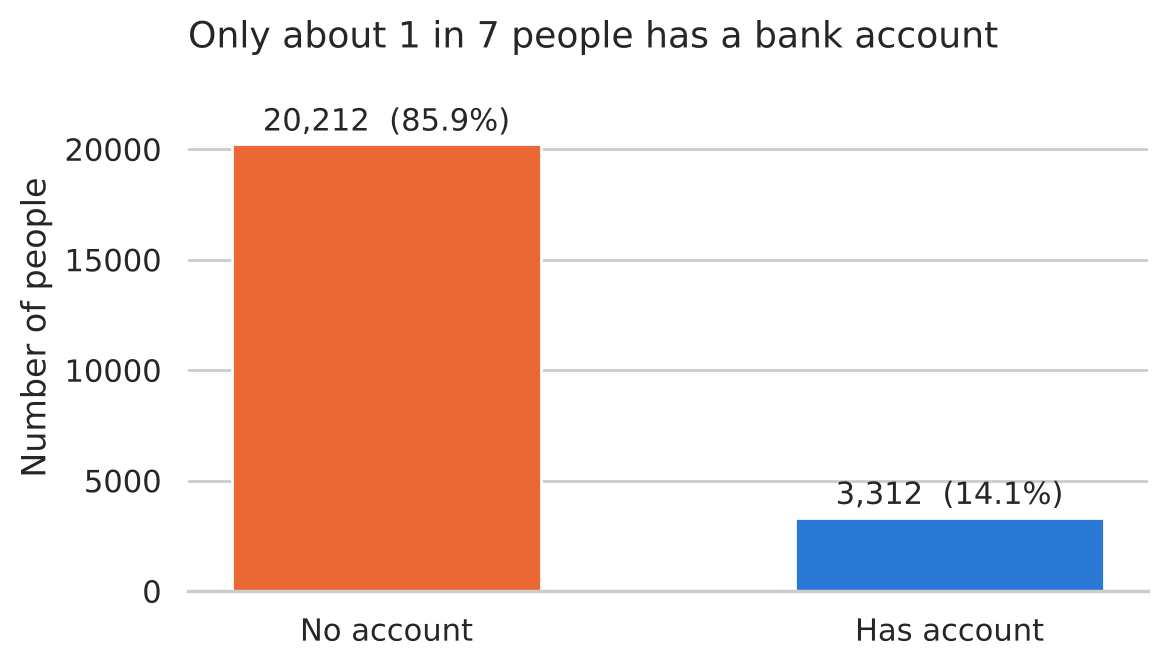

In [5]:
counts = df["bank_account"].value_counts()
pct = df["bank_account"].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({"count": counts, "percent": pct}))

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(["No account", "Has account"], [counts["No"], counts["Yes"]],
              color=[COLORS["No"], COLORS["Yes"]], width=0.55)
for b, n, p in zip(bars, [counts["No"], counts["Yes"]], [pct["No"], pct["Yes"]]):
    ax.text(b.get_x() + b.get_width() / 2, n + 300, f"{n:,}  ({p}%)",
            ha="center", va="bottom", fontsize=11)
ax.set_title("Only about 1 in 7 people has a bank account", loc="left", fontsize=13)
ax.set_ylabel("Number of people")
ax.set_ylim(0, counts.max() * 1.18)
ax.grid(axis="x", visible=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**What we learn:** about **86% have no account** and only **14% have one**. This is an **imbalanced** dataset. Keep the number **86%** in mind: a model that always answers "No" would already be 86% accurate.

### 4.4 Which groups are more likely to have an account?
A simple and powerful exploration trick: for each category, compute **the share of people who have an account**. Big differences between categories mean the column is useful for prediction.

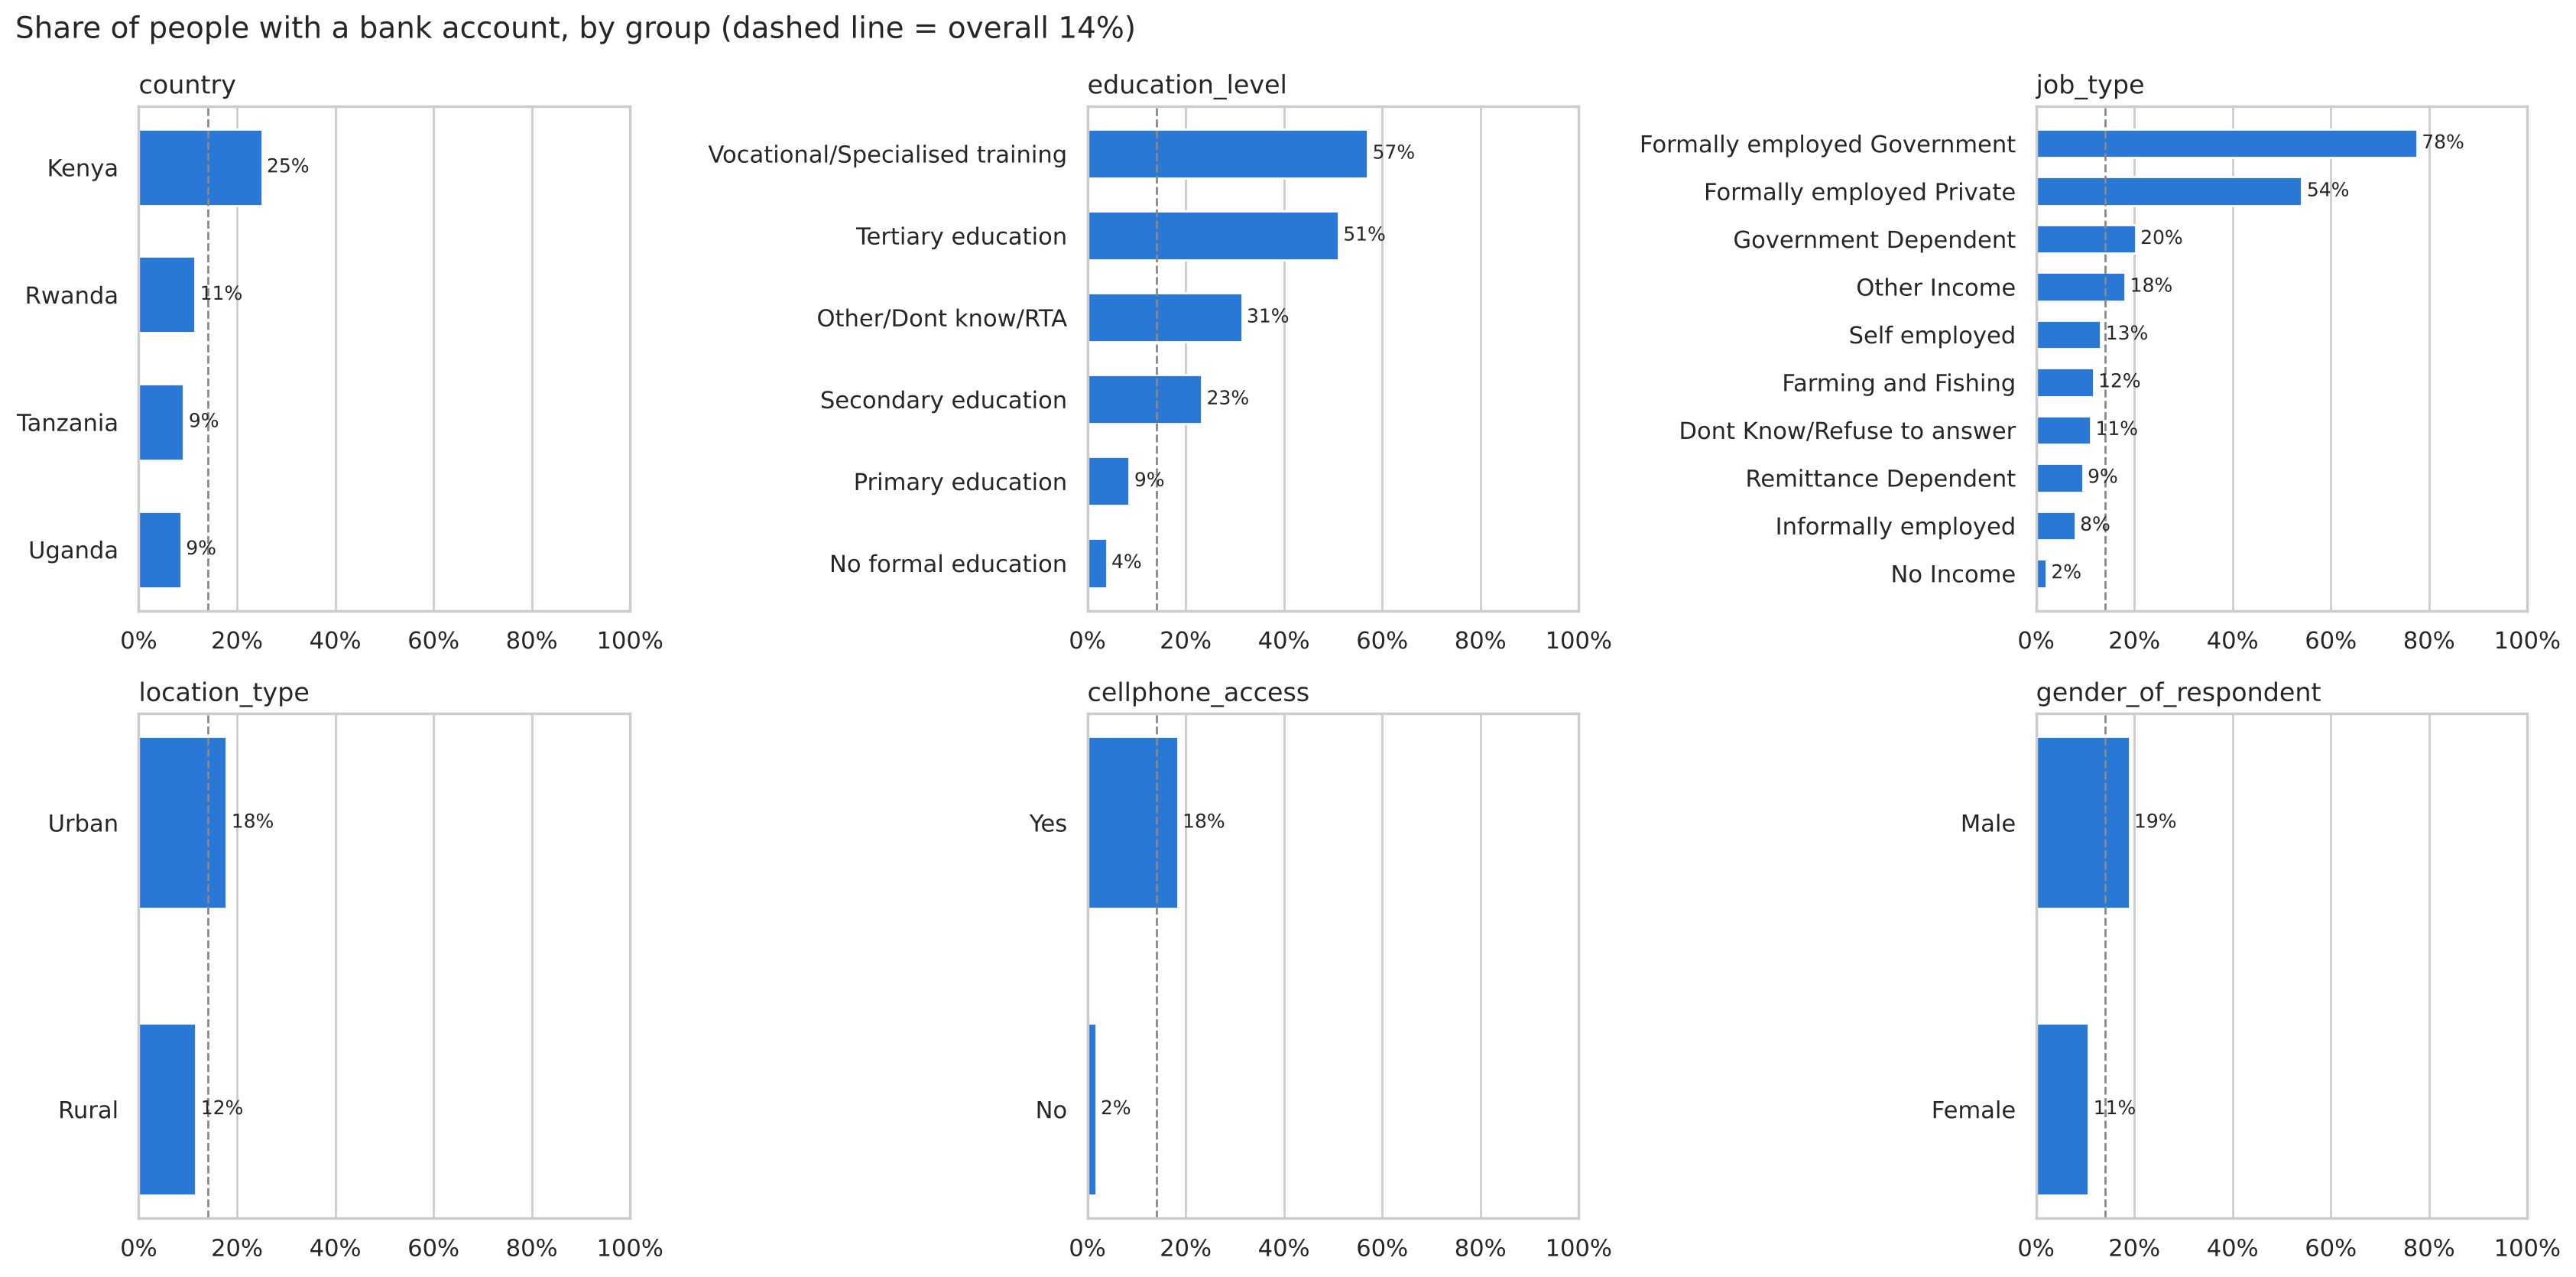

In [6]:
# Turn the label into 1/0 so that its mean is the "share with an account"
df["has_account"] = (df["bank_account"] == "Yes").astype(int)

def ownership_rate(col):
    # Share of people with a bank account, for each category of `col`
    return df.groupby(col)["has_account"].mean().sort_values()

panels = ["country", "education_level", "job_type", "location_type",
          "cellphone_access", "gender_of_respondent"]
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
overall = df["has_account"].mean()
for ax, col in zip(axes.ravel(), panels):
    rate = ownership_rate(col)
    ax.barh(rate.index, rate.values, color=BLUE, height=0.6)
    for i, v in enumerate(rate.values):
        ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9)
    ax.axvline(overall, color=GREY, linestyle="--", linewidth=1)
    ax.set_title(col, loc="left", fontsize=12)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
fig.suptitle("Share of people with a bank account, by group (dashed line = overall 14%)",
             x=0.01, ha="left", fontsize=14)
plt.tight_layout()
plt.show()

**What we learn (these are the "insights" you would share with a manager):**
- **Education** is the strongest signal: people with tertiary or vocational education are many times more likely to be banked than those with no formal education.
- **Formal employment** (government or private) goes with high ownership; farming, informal work and remittance dependence go with low ownership.
- **Kenya** has much higher ownership than Rwanda, Tanzania or Uganda.
- **Urban** dwellers, **men** and people with **phone access** are more likely to be banked.

⚠️ These are **associations**, not causes. Education may not *cause* account ownership directly; it may go together with income, which we don't observe.

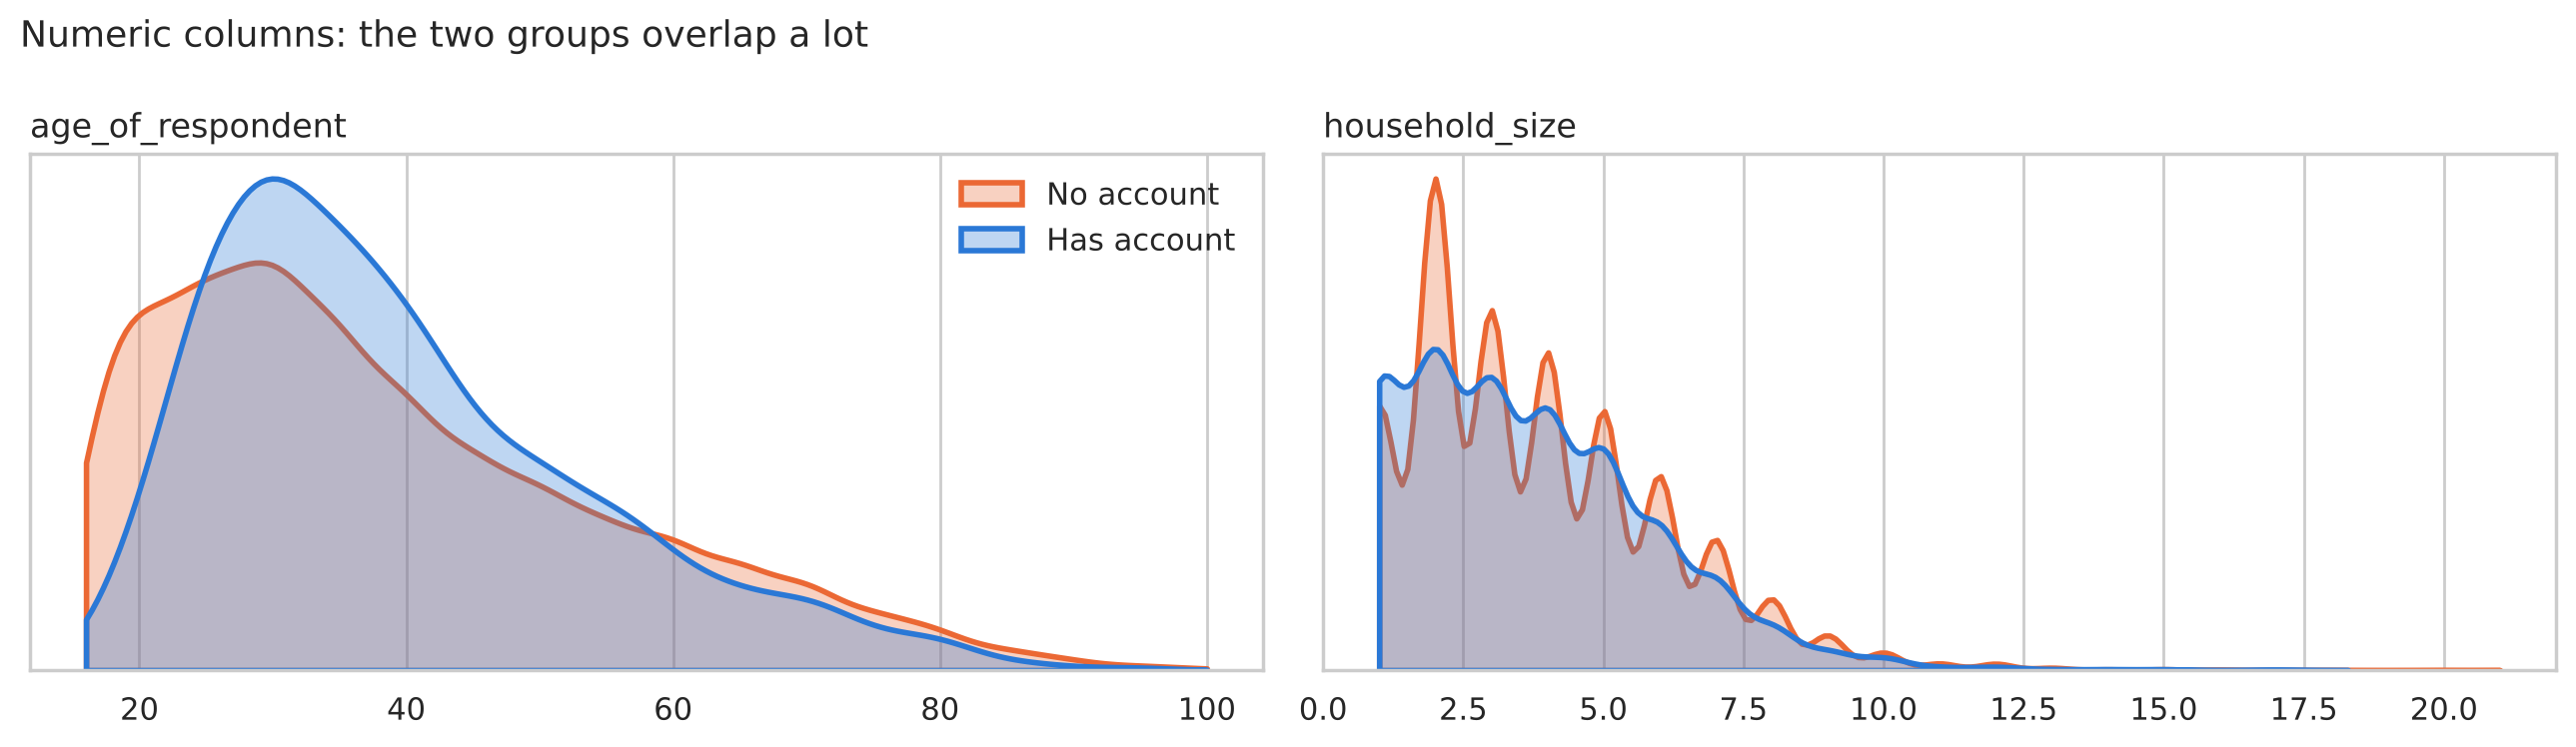

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col in zip(axes, ["age_of_respondent", "household_size"]):
    for label, name in [("No", "No account"), ("Yes", "Has account")]:
        sns.kdeplot(df.loc[df["bank_account"] == label, col], ax=ax, fill=True,
                    alpha=0.3, linewidth=2, color=COLORS[label], label=name,
                    common_norm=False, clip=(df[col].min(), df[col].max()))
    ax.set_title(col, loc="left", fontsize=12)
    ax.set_xlabel("")
    ax.set_yticks([])
    ax.set_ylabel("")
axes[0].legend(frameon=False)
fig.suptitle("Numeric columns: the two groups overlap a lot", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

**What we learn:** account holders are slightly more often aged 25–45, but the two curves overlap heavily. Age and household size are **weak** signals on their own. A model combines many weak and strong signals at once.

### 4.5 Which columns should we NOT use?
- **`uniqueid`**: just an ID number. It carries no real information, and a model could "memorise" IDs. **Drop it.**
- **`year`**: each country was surveyed in only one year, so `year` simply repeats `country`. It would also be meaningless for future predictions. **Drop it.**
- **`bank_account`** / **`has_account`**: this is the answer. Putting the answer in the inputs is called **data leakage** and is the most common beginner mistake.

In [8]:
pd.crosstab(df["country"], df["year"])   # proof: one survey year per country

year,2016,2017,2018
country,,,
Kenya,0,0,6068
Rwanda,8735,0,0
Tanzania,0,6620,0
Uganda,0,0,2101


## 5. Prepare the data

### 5.1 Separate features (X) from the label (y)
- `X` = the inputs the model may look at
- `y` = the answer we want it to predict: **1 = has a bank account**, 0 = does not

By convention, the **positive class (1)** is the thing we want to *find*. Here we want to find people who have accounts.

In [9]:
categorical_cols = ["country", "location_type", "cellphone_access", "gender_of_respondent",
                    "relationship_with_head", "marital_status", "education_level", "job_type"]
numeric_cols = ["household_size", "age_of_respondent"]

X = df[categorical_cols + numeric_cols]
y = df["has_account"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (23524, 10)
y shape: (23524,)


### 5.2 Train / test split
Think of it like school:
- **Training set (80%)** = the textbook and practice questions the model studies.
- **Test set (20%)** = the final exam, which the model never sees while studying.

If we test on data the model has already seen, we measure *memory*, not *understanding*.

- `stratify=y` keeps the same 86/14 class mix in both sets (very important for imbalanced data).
- `random_state=42` makes the split identical every time (reproducible).

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          # 20% held out for the final exam
    stratify=y,              # keep the class balance the same in both sets
    random_state=RANDOM_STATE,
)

print(f"Training set: {len(X_train):,} people  |  share with account = {y_train.mean():.1%}")
print(f"Test set:     {len(X_test):,} people  |  share with account = {y_test.mean():.1%}")

Training set: 18,819 people  |  share with account = 14.1%
Test set:     4,705 people  |  share with account = 14.1%


### 5.3 Turning text into numbers: one-hot encoding
Models only understand numbers. We cannot just number the categories (Kenya = 1, Rwanda = 2, …) because the model would think Rwanda is "twice" Kenya.

**One-hot encoding** creates one new 0/1 column per category instead:

| country | → | country_Kenya | country_Rwanda | country_Tanzania | country_Uganda |
|---|---|---|---|---|---|
| Kenya | | 1 | 0 | 0 | 0 |
| Uganda | | 0 | 0 | 0 | 1 |

Here is a tiny demo:

In [11]:
demo = pd.DataFrame({"country": ["Kenya", "Uganda", "Rwanda", "Kenya"]})
pd.get_dummies(demo, dtype=int)

,country_Kenya,country_Rwanda,country_Uganda
0,1,0,0
1,0,0,1
2,0,1,0
3,1,0,0


### 5.4 Scaling numbers and building a preprocessing pipeline
Numeric columns live on different scales (age up to 100, household size up to ~20). Some models (like Logistic Regression) work better when every number is rescaled to **mean 0, standard deviation 1**. `StandardScaler` does this.

A `ColumnTransformer` applies the right step to the right columns:
- categorical columns → `OneHotEncoder`
- numeric columns → `StandardScaler`

**Golden rule:** the encoder and scaler must **learn only from the training set**. Wrapping everything in a `Pipeline` guarantees this, because `fit` is only ever called on training data.

In [12]:
preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", StandardScaler(), numeric_cols),
    ],
    verbose_feature_names_out=False,   # keep readable column names
)

# Peek at what the model will actually see
preprocess.fit(X_train)
feature_names = preprocess.get_feature_names_out()
print(f"{X_train.shape[1]} original columns  →  {len(feature_names)} model-ready columns")
print(list(feature_names[:12]), "...")

10 original columns  →  39 model-ready columns
['country_Kenya', 'country_Rwanda', 'country_Tanzania', 'country_Uganda', 'location_type_Rural', 'location_type_Urban', 'cellphone_access_No', 'cellphone_access_Yes', 'gender_of_respondent_Female', 'gender_of_respondent_Male', 'relationship_with_head_Child', 'relationship_with_head_Head of Household'] ...


## 6. Start with a baseline

A **baseline** is the score you get with zero intelligence. Our dumbest possible model always predicts the most common answer ("No account"). Any real model must beat this, or it is worthless.

In [13]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)

print(f"Baseline accuracy: {accuracy_score(y_test, y_pred_base):.1%}")
print(f"Baseline recall (account holders found): {recall_score(y_test, y_pred_base):.1%}")

Baseline accuracy: 85.9%
Baseline recall (account holders found): 0.0%


**This is the key lesson of the session:** the baseline is about **86% accurate** but finds **0%** of the account holders.
On imbalanced data, a high accuracy number can hide a model that fails at the one job we care about.

## 7. Train our first real model: Logistic Regression 

Despite the name, **Logistic Regression is a classification model**. It:
1. Gives each feature a weight (a coefficient).
2. Adds up `weight × feature value` to get a score.
3. Squashes that score into a **probability between 0 and 1** using the S-shaped *sigmoid* curve.
4. If the probability is ≥ 0.5, it predicts **"has account"**.

Every scikit-learn model follows the same three steps:
```python
model = SomeModel()          # 1. create
model.fit(X_train, y_train)  # 2. learn from training data
model.predict(X_test)        # 3. predict on new data
```

In [14]:
log_reg = Pipeline([
    ("prep", preprocess),                                            # step 1: encode + scale
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),  # step 2: classify
])
log_reg.fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)                 # hard answers: 0 or 1
y_proba_lr = log_reg.predict_proba(X_test)[:, 1]    # probability of "has account"

# Look at the first 8 test people side by side
preview = X_test.iloc[:8][["country", "education_level", "job_type"]].copy()
preview["actual"] = y_test.values[:8]
preview["predicted"] = y_pred_lr[:8]
preview["P(has account)"] = y_proba_lr[:8].round(3)
preview

,country,education_level,job_type,actual,predicted,P(has account)
69,Kenya,Secondary education,Formally employed Private,1,1,0.725
13395,Rwanda,Primary education,Remittance Dependent,0,0,0.077
18888,Tanzania,No formal education,Self employed,0,0,0.041
4660,Kenya,Primary education,Informally employed,0,0,0.017
13090,Rwanda,Primary education,Farming and Fishing,0,0,0.076
13444,Rwanda,Secondary education,Self employed,0,0,0.198
15565,Tanzania,Primary education,Remittance Dependent,0,0,0.028
6723,Rwanda,Primary education,Informally employed,0,0,0.097


## 8. Evaluate the model

### 8.1 The confusion matrix
The confusion matrix counts every kind of right and wrong answer:

| | **Predicted: no account** | **Predicted: has account** |
|---|---|---|
| **Actually no account** |  True Negative (TN) | False Positive (FP): a wrong "yes" |
| **Actually has account** | False Negative (FN): a missed account holder | True Positive (TP) |

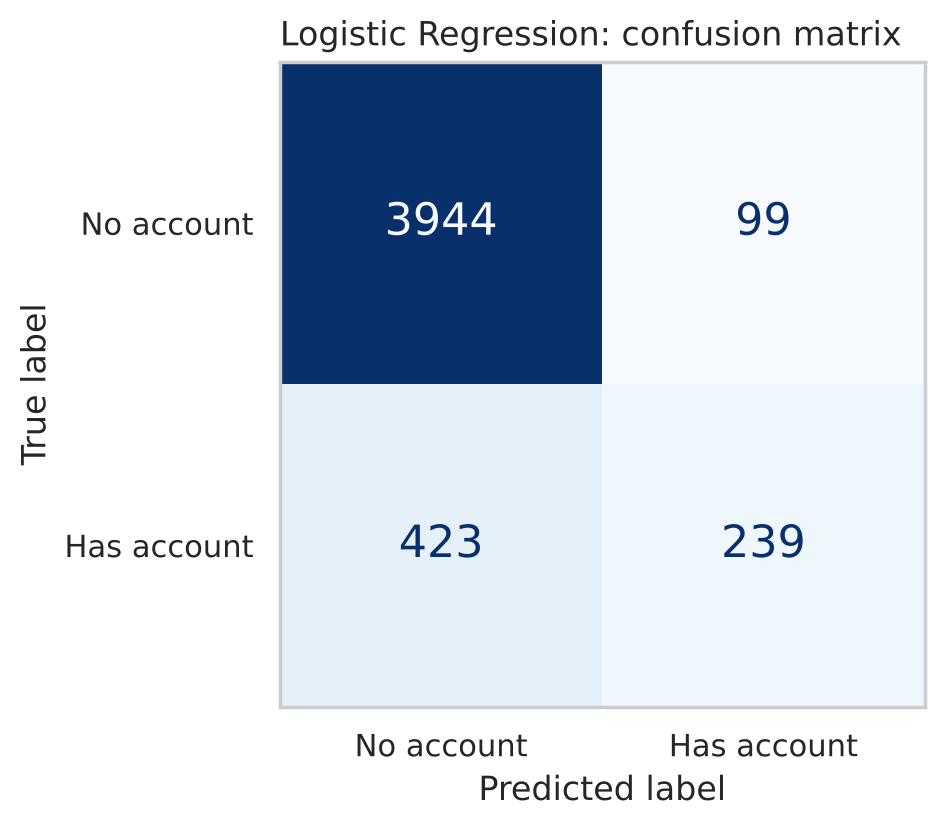

TN=3944  FP=99  FN=423  TP=239


In [15]:
fig, ax = plt.subplots(figsize=(5.2, 4.3))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr,
    display_labels=["No account", "Has account"],
    cmap="Blues", colorbar=False, ax=ax,
    text_kw={"fontsize": 16},
)
ax.set_title("Logistic Regression: confusion matrix", loc="left", fontsize=12)
ax.grid(False)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_lr).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

### 8.2 The four key metrics

| Metric | Formula | Plain-English question it answers |
|---|---|---|
| **Accuracy** | (TP + TN) / all | Out of everyone, how many did we get right? |
| **Precision** | TP / (TP + FP) | When we say "has account", how often are we right? |
| **Recall** (sensitivity) | TP / (TP + FN) | Out of all real account holders, how many did we find? |
| **F1 score** | 2 × P × R / (P + R) | A single balance of precision and recall |

**Memory trick:** **P**recision = how **P**ure our "yes" answers are. **R**ecall = how many of the real "yes" cases we **R**etrieved.

In [16]:
def evaluate(name, y_true, y_pred, y_proba=None):
    # Return the key classification metrics for one model as a dictionary.
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    result = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "missed (FN)": fn,
        "wrong yes (FP)": fp,
    }
    if y_proba is not None:
        result["ROC AUC"] = roc_auc_score(y_true, y_proba)
    return result

lr_scores = evaluate("Logistic Regression", y_test, y_pred_lr, y_proba_lr)
pd.Series(lr_scores).to_frame("value")

,value
model,Logistic Regression
accuracy,0.889054
precision,0.707101
recall,0.361027
f1,0.478
missed (FN),423
wrong yes (FP),99
ROC AUC,0.864172


scikit-learn can also print a full report in one line:

In [17]:
print(classification_report(y_test, y_pred_lr, target_names=["No account", "Has account"], digits=3))

              precision    recall  f1-score   support

  No account      0.903     0.976     0.938      4043
 Has account      0.707     0.361     0.478       662

    accuracy                          0.889      4705
   macro avg      0.805     0.668     0.708      4705
weighted avg      0.876     0.889     0.873      4705



**How to read the report:** each row is one class. `support` is how many people of that class are in the test set.

Notice the pattern: the model is excellent on the big "No account" class but **only finds about a third of the account holders** (recall around 0.35). Accuracy (~89%) hides this. We will fix it in Section 10.

## 9. Try other models

### 9.1 Decision Tree
A decision tree asks a series of yes/no questions, like a flowchart: *"Formally employed in the private sector? → Primary education only? → Older than 30? …"*.
- Very easy to explain to non-technical people.
- Grown too deep, it memorises the training data (**overfitting**).

We limit `max_depth=3` so the tree stays small and readable.

Trees don't need scaling, so here we one-hot encode the text columns but pass age and household size through unchanged (`"passthrough"`). That way the tree's questions use real ages in years.

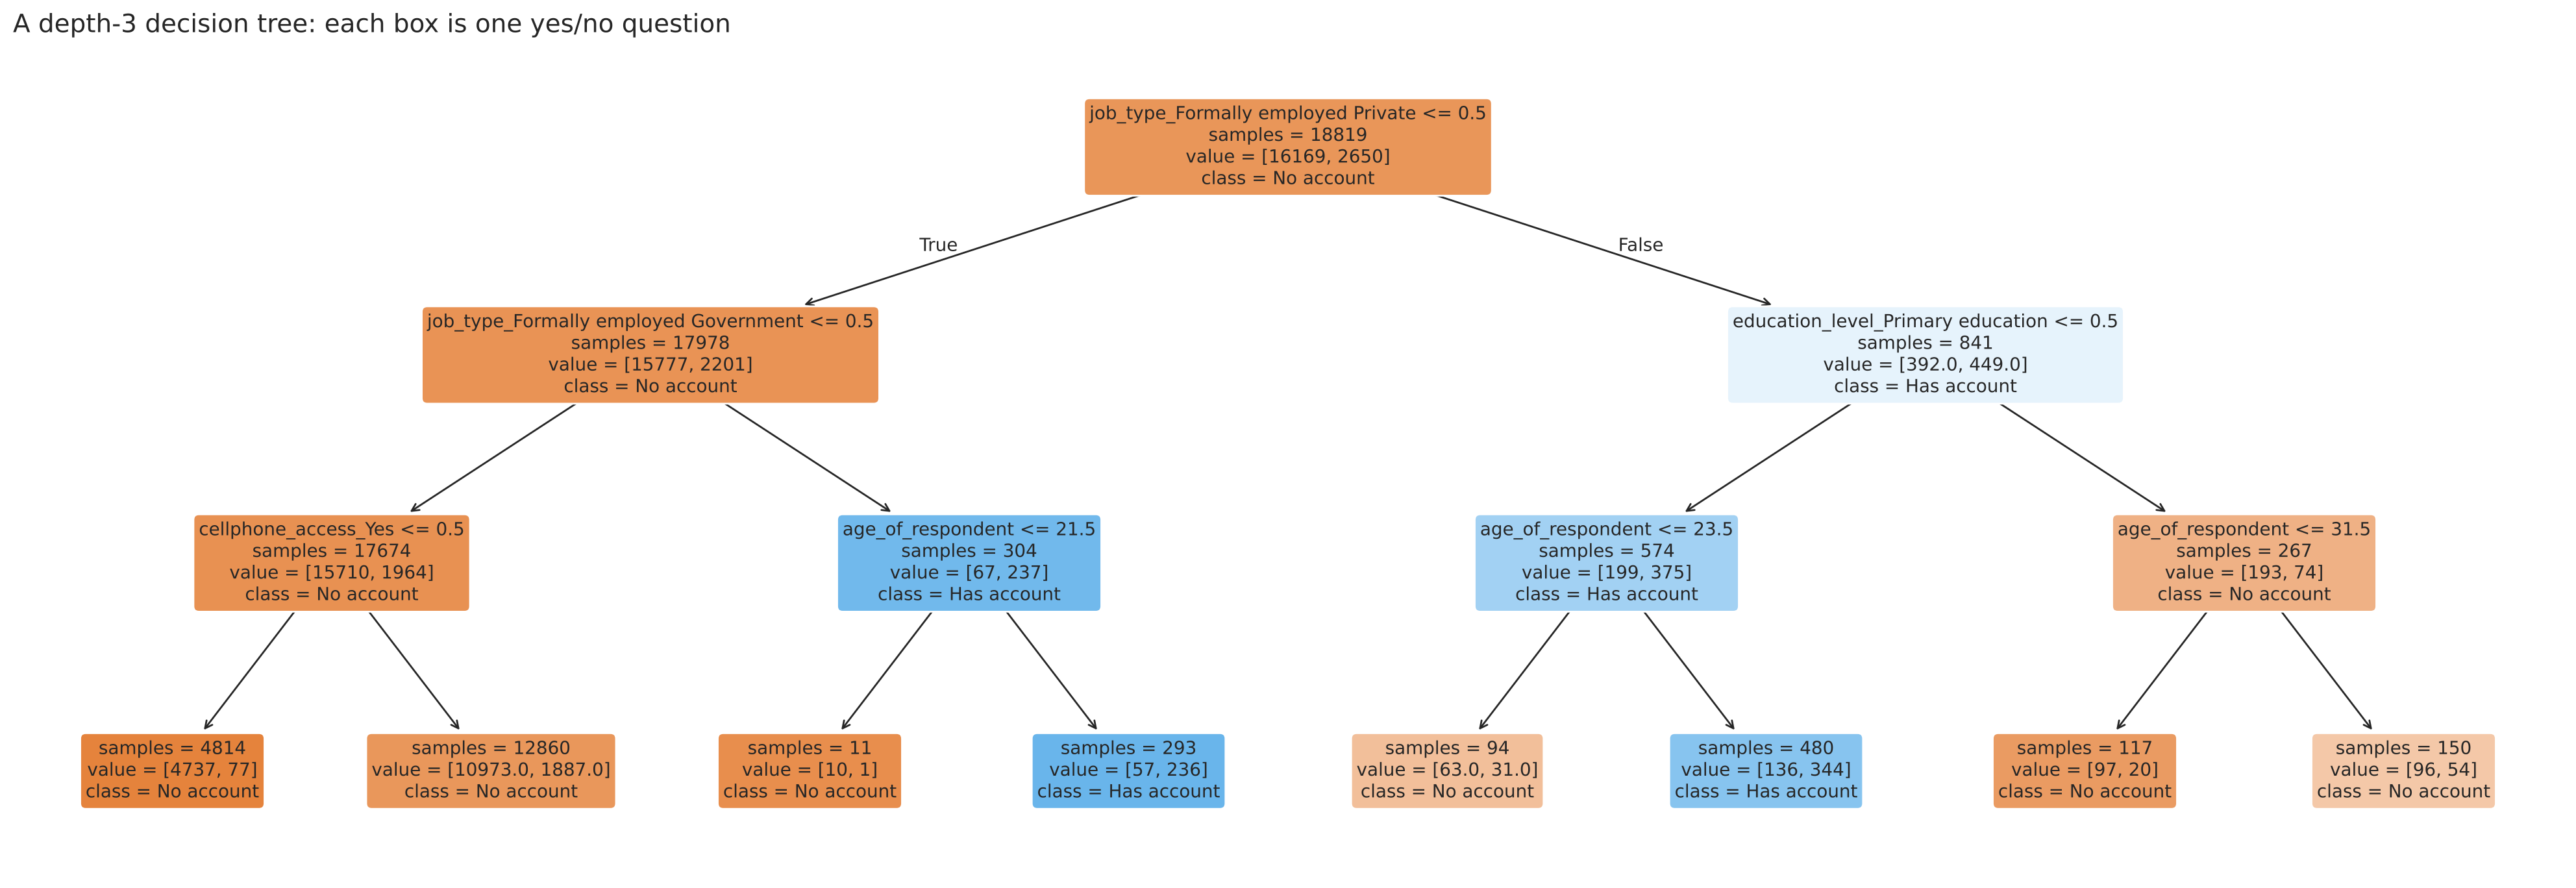

In [18]:
tree_prep = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols),     # keep real ages, no scaling needed for trees
    ],
    verbose_feature_names_out=False,
)
tree = Pipeline([
    ("prep", tree_prep),
    ("model", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)),
])
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)
y_proba_tree = tree.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(tree.named_steps["model"], feature_names=tree.named_steps["prep"].get_feature_names_out(),
          class_names=["No account", "Has account"], filled=True, rounded=True,
          fontsize=10, impurity=False, ax=ax)
ax.set_title("A depth-3 decision tree: each box is one yes/no question", loc="left", fontsize=14)
plt.tight_layout()
plt.show()

**How to read the tree:** start at the top box. A one-hot column like `job_type_Formally employed Private <= 0.5` means "is NOT formally employed in the private sector". If the condition is **true**, go **left**; if **false**, go **right**. Each bottom box (leaf) gives the prediction. `value` shows [no account, has account] counts of training people in that box.

### 9.2 Random Forest
A **random forest** trains *many* decision trees, each on a random sample of the people and columns, then lets them **vote**. The "wisdom of the crowd" usually beats any single tree and overfits less.

In [19]:
forest = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                     random_state=RANDOM_STATE, n_jobs=-1)),
])
forest.fit(X_train, y_train)
y_pred_rf = forest.predict(X_test)
y_proba_rf = forest.predict_proba(X_test)[:, 1]
print("Random forest trained with", len(forest.named_steps["model"].estimators_), "trees")

Random forest trained with 300 trees 🌲


### 9.3 Compare all models side by side

In [20]:
results = pd.DataFrame([
    evaluate("Baseline (always No)", y_test, y_pred_base),
    lr_scores,
    evaluate("Decision Tree (depth 3)", y_test, y_pred_tree, y_proba_tree),
    evaluate("Random Forest", y_test, y_pred_rf, y_proba_rf),
]).set_index("model")

results.style.format({
    "accuracy": "{:.1%}", "precision": "{:.1%}", "recall": "{:.1%}",
    "f1": "{:.3f}", "ROC AUC": "{:.3f}",
}, na_rep="–").background_gradient(subset=["recall", "f1"], cmap="Greens")

,accuracy,precision,recall,f1,missed (FN),wrong yes (FP),ROC AUC
model,,,,,,,
Baseline (always No),85.9%,0.0%,0.0%,0.000,662,0,–
Logistic Regression,88.9%,70.7%,36.1%,0.478,423,99,0.864
Decision Tree (depth 3),88.2%,75.0%,24.5%,0.369,500,54,0.718
Random Forest,88.9%,72.5%,33.8%,0.461,438,85,0.874


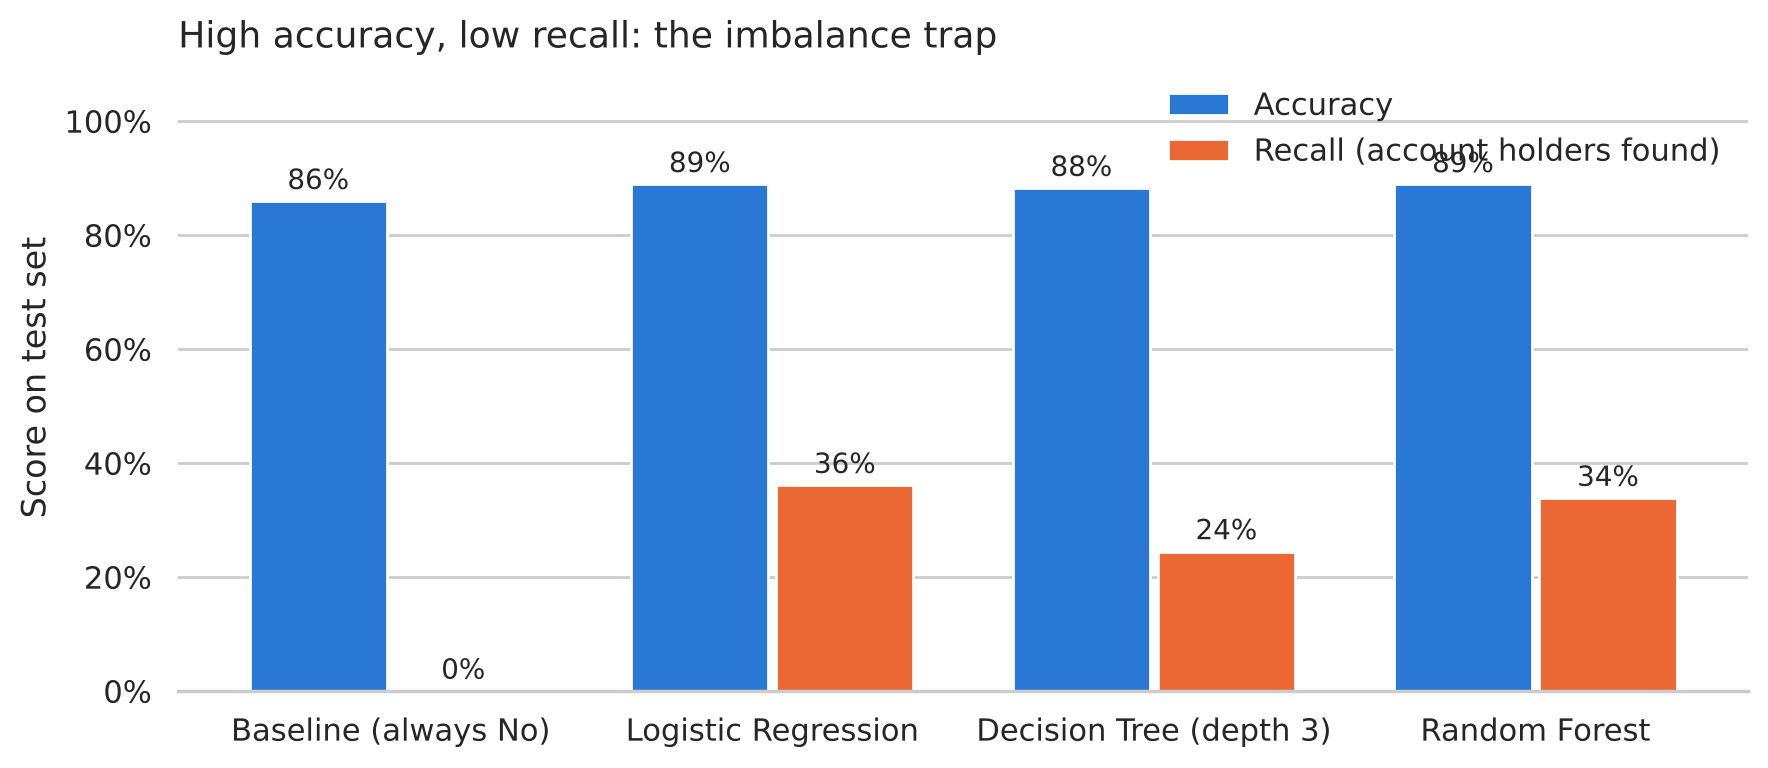

In [21]:
plot_df = results[["accuracy", "recall"]]
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(plot_df))
w = 0.36
b1 = ax.bar(x - w/2 - 0.01, plot_df["accuracy"], w, label="Accuracy", color=BLUE)
b2 = ax.bar(x + w/2 + 0.01, plot_df["recall"], w, label="Recall (account holders found)", color=ORANGE)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                f"{b.get_height():.0%}", ha="center", va="bottom", fontsize=10)
ax.set_xticks(x, plot_df.index)
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Score on test set")
ax.set_title("High accuracy, low recall: the imbalance trap", loc="left", fontsize=13)
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

### 9.4 Don't trust one split: cross-validation
Scores can shift a little depending on which people landed in the test set. **Cross-validation** splits the *training* data into 5 parts ("folds"), trains on 4 and tests on the 5th, and repeats 5 times. The **average** is a more reliable estimate.

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {"Logistic Regression": log_reg, "Decision Tree (depth 3)": tree, "Random Forest": forest}

cv_rows = []
for name, model in models.items():
    f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
    acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    cv_rows.append({"model": name,
                    "CV accuracy (mean ± sd)": f"{acc.mean():.1%} ± {acc.std():.1%}",
                    "CV F1 (mean ± sd)": f"{f1.mean():.3f} ± {f1.std():.3f}"})
pd.DataFrame(cv_rows).set_index("model")

,CV accuracy (mean ± sd),CV F1 (mean ± sd)
model,,
Logistic Regression,88.4% ± 0.4%,0.449 ± 0.031
Decision Tree (depth 3),87.7% ± 0.4%,0.334 ± 0.034
Random Forest,88.7% ± 0.4%,0.443 ± 0.023


**What we learn:** the ± tells us how much the score wobbles between folds. All three models are close; differences smaller than the ± are probably just noise.

### 9.5 ROC curve: performance at every threshold
Each model outputs a probability and uses a **threshold of 0.5** to decide. The **ROC curve** shows what happens across *all* thresholds:
- x-axis: false-positive rate (wrong "yes" among people with no account)
- y-axis: true-positive rate (= recall)

A perfect model hugs the top-left corner. **AUC** (area under the curve) summarises it: 1.0 is perfect, 0.5 is a coin flip.

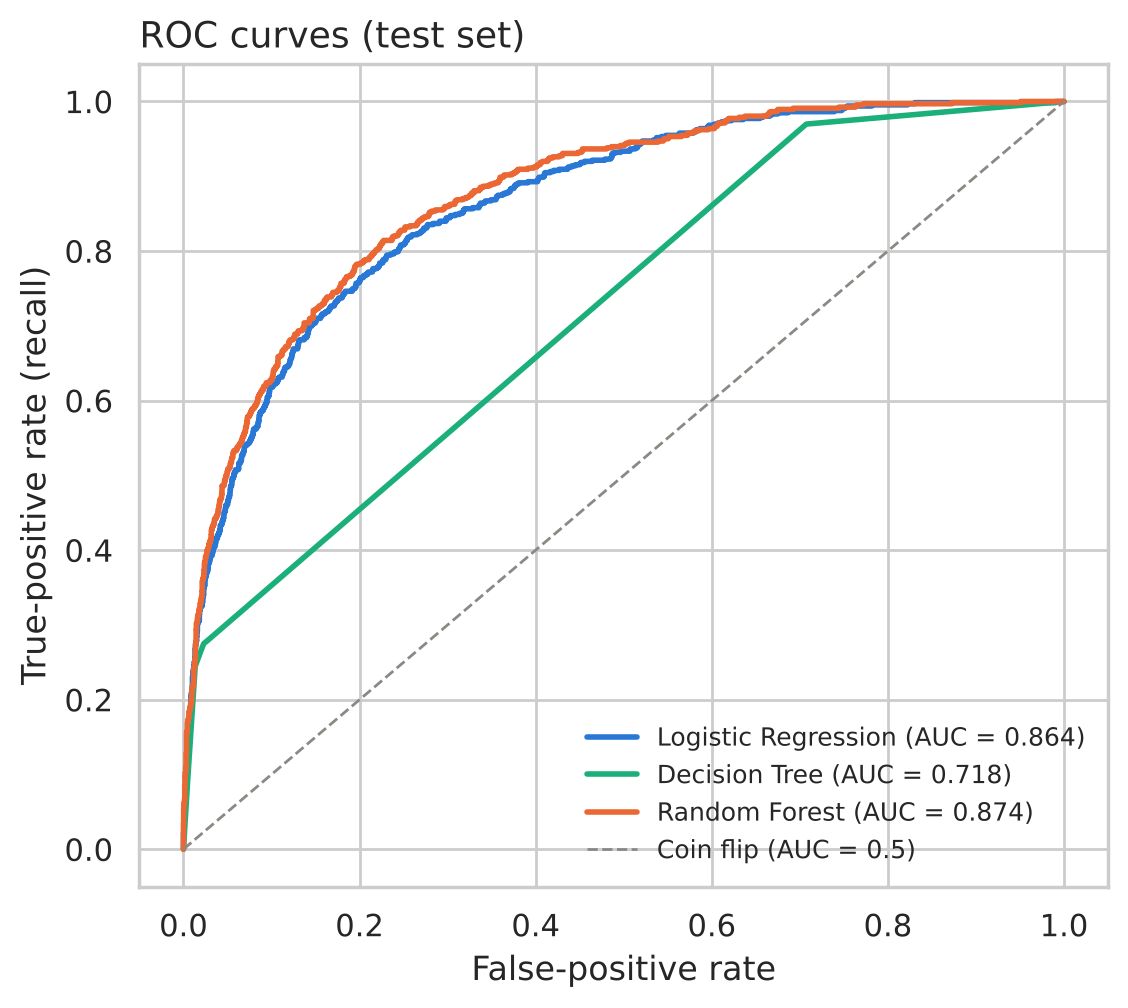

In [23]:
fig, ax = plt.subplots(figsize=(5.8, 5.2))
for name, proba, color in [
    ("Logistic Regression", y_proba_lr, BLUE),
    ("Decision Tree", y_proba_tree, GREEN),
    ("Random Forest", y_proba_rf, ORANGE),
]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=color, linewidth=2,
            label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color=GREY, linewidth=1, label="Coin flip (AUC = 0.5)")
ax.set_title("ROC curves (test set)", loc="left", fontsize=13)
ax.set_xlabel("False-positive rate")
ax.set_ylabel("True-positive rate (recall)")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## 10. Improve what matters: handling the imbalance

Our models find only about a third of account holders. Two simple fixes:

### Fix 1: `class_weight="balanced"`
Tell the model that a mistake on the rare class (has account) costs more. scikit-learn weights each class inversely to how common it is, so the 14% class counts roughly 6× more.

### Fix 2: move the decision threshold
Instead of saying "yes" only when P ≥ 0.5, say "yes" at a lower probability. More "yes" answers → more account holders found (recall ↑), but more wrong "yes" answers too (precision ↓).

There is no free lunch. The right balance is a **business decision**. Example: a bank sending a cheap SMS campaign can afford many wrong "yes" answers; a costly door-to-door visit cannot.

In [24]:
log_reg_bal = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])
log_reg_bal.fit(X_train, y_train)
y_pred_bal = log_reg_bal.predict(X_test)
y_proba_bal = log_reg_bal.predict_proba(X_test)[:, 1]

compare = pd.DataFrame([
    lr_scores,
    evaluate("Logistic Regression (balanced)", y_test, y_pred_bal, y_proba_bal),
]).set_index("model")
compare.style.format({"accuracy": "{:.1%}", "precision": "{:.1%}", "recall": "{:.1%}",
                      "f1": "{:.3f}", "ROC AUC": "{:.3f}"})

,accuracy,precision,recall,f1,missed (FN),wrong yes (FP),ROC AUC
model,,,,,,,
Logistic Regression,88.9%,70.7%,36.1%,0.478,423,99,0.864
Logistic Regression (balanced),79.1%,38.0%,76.1%,0.507,158,824,0.865


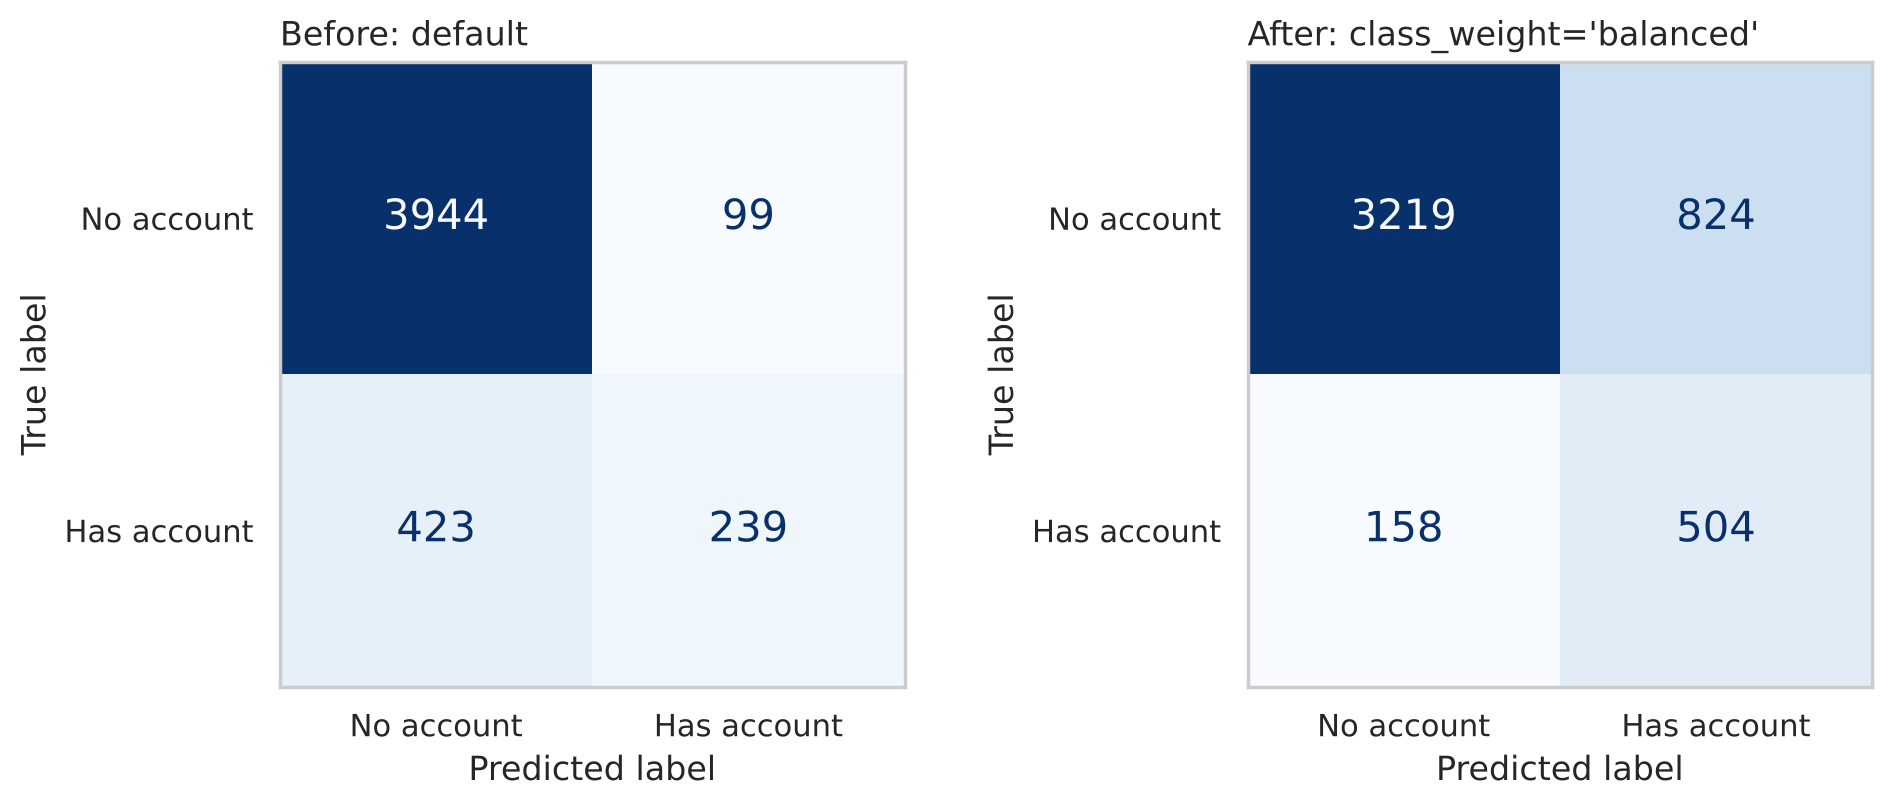

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, pred, title in [(axes[0], y_pred_lr, "Before: default"),
                        (axes[1], y_pred_bal, "After: class_weight='balanced'")]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["No account", "Has account"],
        cmap="Blues", colorbar=False, ax=ax, text_kw={"fontsize": 15})
    ax.set_title(title, loc="left", fontsize=12)
    ax.grid(False)
plt.tight_layout()
plt.show()

**What we learn:** accuracy goes **down**, but recall jumps a lot: the model now finds most account holders. Whether that is "better" depends on what the predictions are used for. That is exactly why you must pick your metric **before** you start modelling.

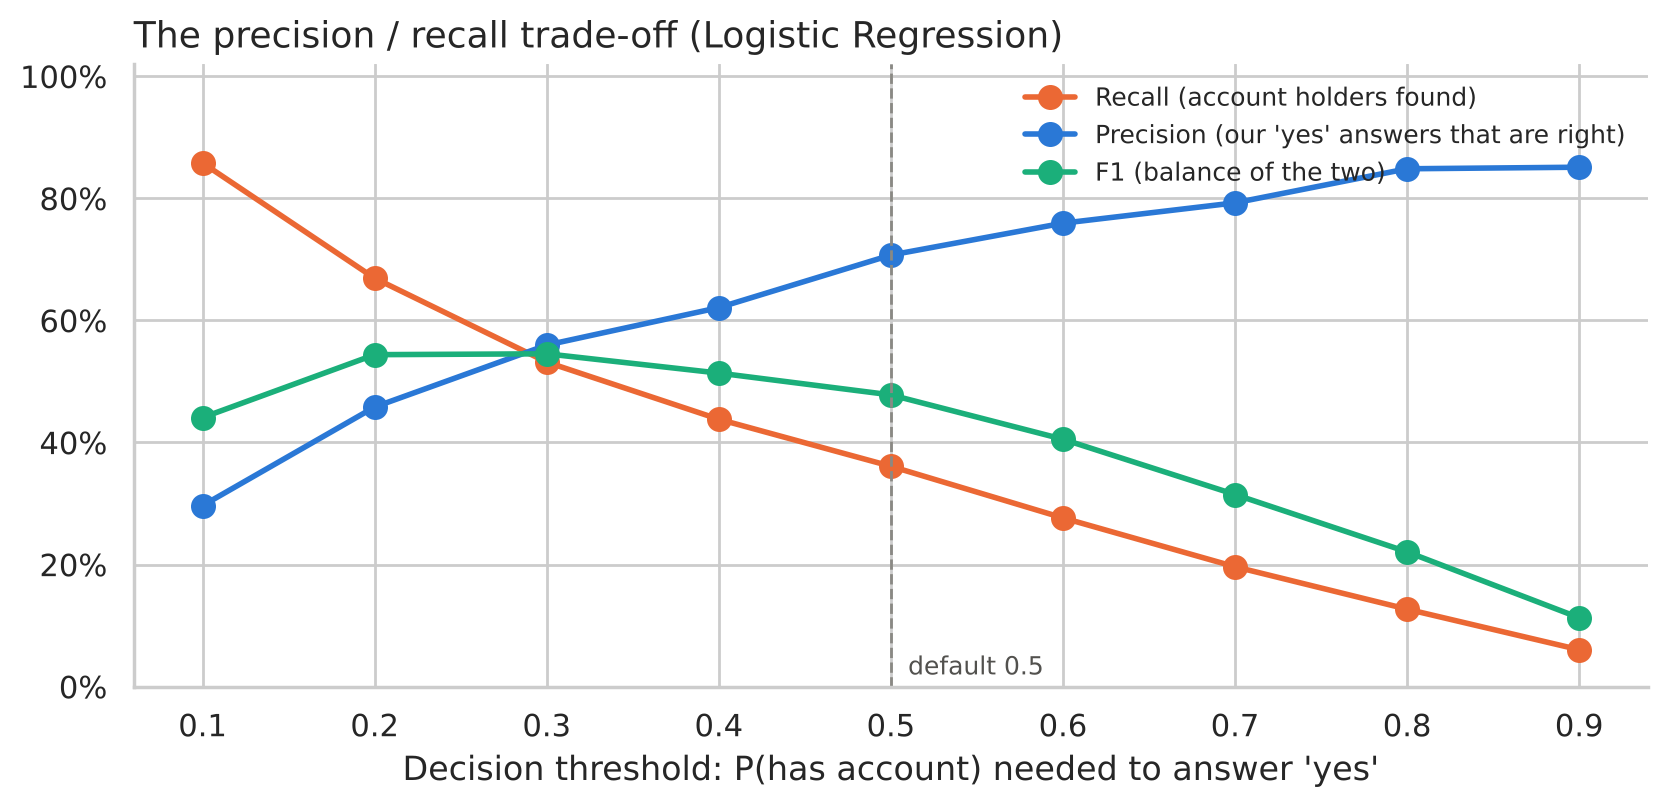

Best F1 on this chart at threshold 0.3: F1=0.545, recall=53.2%, precision=56.0%


In [26]:
thresholds = np.round(np.arange(0.1, 0.91, 0.1), 1)
rows = []
for t in thresholds:
    pred_t = (y_proba_lr >= t).astype(int)
    rows.append({"threshold": t,
                 "recall": recall_score(y_test, pred_t),
                 "precision": precision_score(y_test, pred_t, zero_division=0),
                 "f1": f1_score(y_test, pred_t, zero_division=0)})
thr_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(thr_df["threshold"], thr_df["recall"], marker="o", markersize=8, linewidth=2,
        color=ORANGE, label="Recall (account holders found)")
ax.plot(thr_df["threshold"], thr_df["precision"], marker="o", markersize=8, linewidth=2,
        color=BLUE, label="Precision (our 'yes' answers that are right)")
ax.plot(thr_df["threshold"], thr_df["f1"], marker="o", markersize=8, linewidth=2,
        color=GREEN, label="F1 (balance of the two)")
ax.axvline(0.5, color=GREY, linestyle="--", linewidth=1)
ax.text(0.51, 0.02, "default 0.5", color="#52514e", fontsize=9)
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Decision threshold: P(has account) needed to answer 'yes'")
ax.set_title("The precision / recall trade-off (Logistic Regression)", loc="left", fontsize=13)
ax.legend(frameon=False, loc="upper right", fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

best = thr_df.loc[thr_df["f1"].idxmax()]
print(f"Best F1 on this chart at threshold {best.threshold}: F1={best.f1:.3f}, "
      f"recall={best.recall:.1%}, precision={best.precision:.1%}")

**Fair-play note:** we picked a threshold by looking at the test set, just to *illustrate* the trade-off. In a real project you choose the threshold on a separate **validation set** (or with cross-validation), and use the test set only once at the very end.

## 11. What did the model learn? 
A model you cannot explain is hard to trust. Logistic Regression gives every one-hot column a **coefficient**:
- **positive** coefficient → pushes the prediction towards "has account"
- **negative** coefficient → pushes it towards "no account"

(Because numeric columns are scaled, coefficients are roughly comparable.)

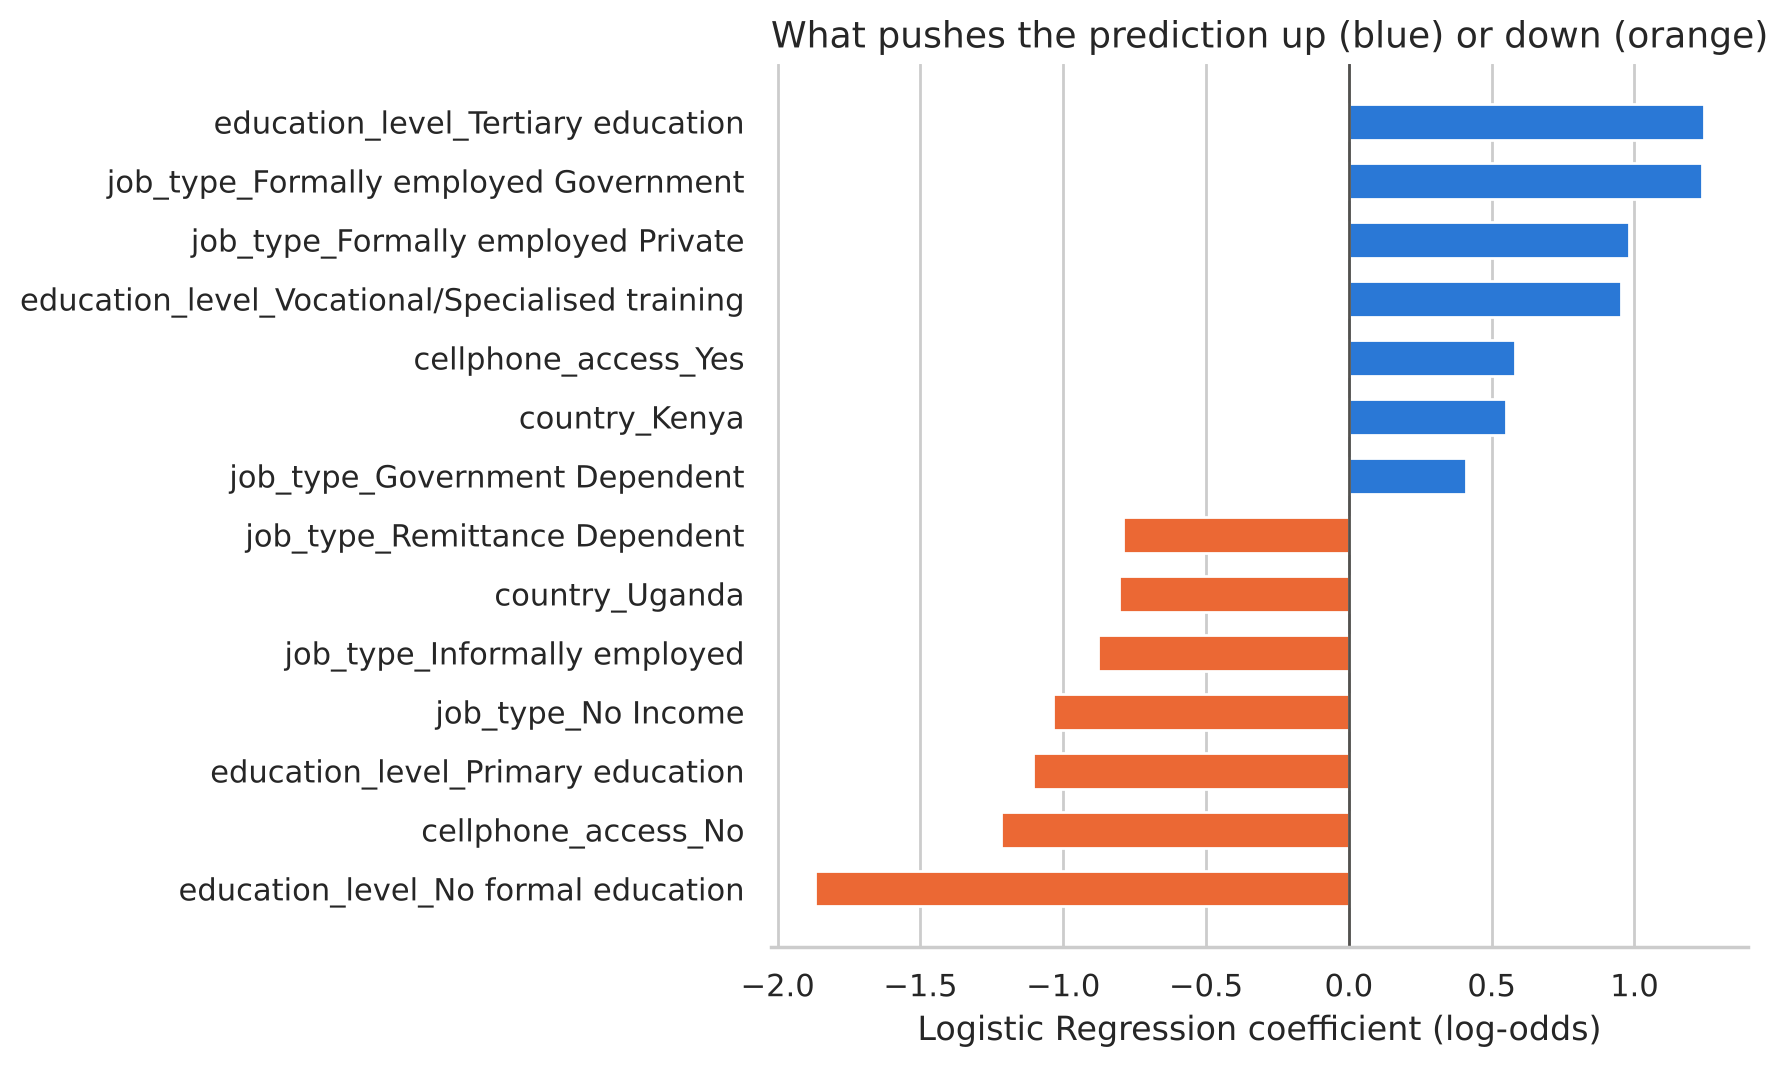

In [27]:
coefs = pd.Series(log_reg.named_steps["model"].coef_[0],
                  index=log_reg.named_steps["prep"].get_feature_names_out())
top = pd.concat([coefs.nsmallest(7), coefs.nlargest(7)]).sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top.values, color=[BLUE if v > 0 else ORANGE for v in top.values], height=0.6)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_title("What pushes the prediction up (blue) or down (orange)", loc="left", fontsize=13)
ax.set_xlabel("Logistic Regression coefficient (log-odds)")
ax.grid(axis="y", visible=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**What we learn:** the model has rediscovered what we saw in the exploration: **tertiary/vocational education, formal employment, phone access and living in Kenya** push towards having an account; **no formal education, no phone, informal work or no income** push away from it. When a model agrees with the exploration, that is a good sanity check.

## 12. Use the model on a new person 
In real life, a trained model receives one new record at a time. Let's describe a person and ask the model. Change the values and re-run to explore!

In [28]:
new_person = pd.DataFrame([{
    "country": "Kenya",
    "location_type": "Urban",
    "cellphone_access": "Yes",
    "gender_of_respondent": "Female",
    "relationship_with_head": "Head of Household",
    "marital_status": "Single/Never Married",
    "education_level": "Tertiary education",
    "job_type": "Formally employed Private",
    "household_size": 2,
    "age_of_respondent": 29,
}])

prob = log_reg_bal.predict_proba(new_person)[0, 1]
print(f"Probability this person has a bank account: {prob:.1%}")
print("Prediction:", " Has account" if prob >= 0.5 else "❌ No account")

Probability this person has a bank account: 97.8%
Prediction: ✅ Has account


## 13. Summary 🎓

| Step | What we did | Key idea |
|---|---|---|
| Frame | Has a bank account: yes/no | Binary classification; positive class = what we want to find |
| Load | `pd.read_csv()` from a file or URL | One line to get data into a DataFrame |
| Explore | Balance, ownership rate by group | Know your data; turn charts into insights |
| Clean | Drop `uniqueid` and `year` | Remove IDs and leaky/useless columns |
| Encode | One-hot + scaling in a pipeline | Models need numbers; fit on training data only |
| Split | 80/20, stratified | Never test on data the model has studied |
| Baseline | Always "No" | ~86% accuracy, 0% recall: accuracy can lie |
| Models | Logistic Regression, Tree, Forest | Same `fit` / `predict` pattern for all |
| Evaluate | Confusion matrix, precision, recall, F1, ROC | Choose the metric that matches the business goal |
| Improve | Class weights, threshold | Trade precision for recall on purpose |
| Explain | Coefficients | Check that the model learned sensible things |

### Three things to remember
1. **Always beat a baseline.**
2. **On imbalanced data, accuracy is not enough.** Look at recall, precision and F1.
3. **Keep the test set sacred.** It is used once, at the very end.

## 14. Practice exercises

1. **Easy:** change `test_size` to 0.3. Do the scores change much? Why?
2. **Easy:** change the Decision Tree's `max_depth` to 1, 6 and `None`. Compare training accuracy (`tree.score(X_train, y_train)`) with test accuracy. Where do you see overfitting?
3. **Medium:** add `class_weight="balanced"` to the Random Forest. How do recall and precision change?
4. **Medium:** train a model **only on Kenya** and test it **on Uganda**. Does it still work? What does this tell you about using a model in a new market?
5. **Medium:** add a new feature `age_group` (e.g. 16–24, 25–34, 35–49, 50+) using `pd.cut`. Does it help?
6. **Challenge:** use `GridSearchCV` to tune `max_depth` and `min_samples_leaf` of the Random Forest, optimising **F1**.
7. **Discussion:** the model uses gender and country. Could it be unfair if a bank used it to decide *who to offer products to*? What could you do about it?

## 15. Glossary

| Term | Meaning |
|---|---|
| Feature | An input column the model uses (e.g. education_level) |
| Label / target | The answer we want to predict (has a bank account) |
| Categorical feature | A column whose values are categories (text), not numbers |
| One-hot encoding | Turning one categorical column into several 0/1 columns |
| Training set | Data the model learns from |
| Test set | Data held back to check the model at the end |
| Imbalanced data | One class is much more common than the other |
| Overfitting | Memorising training data so well that the model fails on new data |
| Data leakage | Letting information about the answer sneak into the inputs |
| Baseline | The score of a "no-intelligence" model; the bar to beat |
| Confusion matrix | Table counting TP, TN, FP and FN |
| Precision | Of our "yes" answers, the share that were right |
| Recall | Of the real "yes" cases, the share we found |
| F1 score | Harmonic mean of precision and recall |
| Threshold | Probability above which we answer "yes" |
| Class weight | Making mistakes on the rare class count more during training |
| ROC AUC | Overall ability to rank positives above negatives (0.5 = random, 1 = perfect) |
| Cross-validation | Repeating train/test on different folds for a more reliable estimate |
| Pipeline | Chains preprocessing and a model so they are always applied together |

**Data source:** *Financial Inclusion in Africa*, Zindi (data from Finscope surveys, 2016–2018). Training file `Train.csv`. Used here for teaching.